# Brain Cancer Type Classification from Tumour Gene Activity Using Machine Learning

**Group members**

| No. | Name | Roll No. |
|---|---|---|
| 1 | Raghav Yadav | 240598 |
| 2 | Saksham Lodha | 240626 |
| 3 | Rayna Manchanda | 240601 |
| 4 | Darshita Yadav | 240981 |
| 5 | Prerit Shrivastava | 240593 |

## Problem Statement
Adult diffuse gliomas (brain tumours) are classified clinically by two molecular markers: **IDH mutation** and **1p/19q chromosome codeletion**. Finding them needs dedicated molecular tests. This project asks whether a tumour's **gene expression (RNA-seq) alone** can predict the glioma type.

**What we predict:** a 3-class label, the `IDH/codel subtype` column of the TCGA Table S1 (Ceccarelli et al., 2016):

| Class | Patients |
|---|---|
| IDHmut-non-codel | 256 |
| IDHwt | 229 |
| IDHmut-codel | 169 |

**Input:** about 20,000 gene expression values per patient (654 patients after joining expression with labels).

**Models:** Logistic Regression, Decision Tree, KNN, and two ensembles - Random Forest (bagging) and XGBoost (boosting).

**Notebook map:** Setup - 1 Data - 2 EDA - 3 Features and split - 4 Base models - 5 Ensemble models - 6 Tuning - 7 Performance analysis - 8 Conclusion

## Motivation
- **Type decides treatment and outlook.** Which kind of glioma a patient has strongly affects the treatment given and the expected survival. The three types run from very aggressive (glioblastoma) through intermediate (astrocytoma) to slow-growing with the best outlook (oligodendroglioma).
- **The test is costly.** Since the 2021 WHO classification, doctors decide the type with genetic lab tests on the tumour, not by microscope alone. These tests are expensive and not available in every hospital.
- **A single measurement may be enough.** One test that measures how active each gene is in the tumour already carries the "fingerprint" of each type. If a model can read that gene-activity profile and name the type, one expression measurement could stand in for several separate lab tests.
- **Why machine learning.** The profile has about 20,000 numbers per patient but only a few hundred patients, so the task needs careful feature handling, regularization and honest evaluation on patients the model has never seen.

## Literature Review
**1. Ceccarelli et al. (2016), *Molecular Profiling Reveals Biologically Discrete Subsets and Pathways of Progression in Diffuse Glioma*, Cell 164(3):550-563.**
A multi-platform molecular study of lower-grade glioma and glioblastoma from The Cancer Genome Atlas. It shows that IDH mutation status and 1p/19q codeletion divide diffuse gliomas into biologically distinct subsets with different outcomes. The study also released the patient table with these labels and the gene-expression matrix, which are the two data files used in this project.

**2. Louis et al. (2021), *The 2021 WHO Classification of Tumors of the Central Nervous System: a summary*, Neuro-Oncology 23(8):1231-1251.**
The current WHO classification defines adult diffuse glioma types using molecular markers as well as appearance under the microscope. The three types relevant here correspond to our classes:

| WHO 2021 type | Molecular definition | Our class |
|---|---|---|
| Glioblastoma | IDH-wildtype | IDHwt |
| Astrocytoma | IDH-mutant, 1p/19q intact | IDHmut-non-codel |
| Oligodendroglioma | IDH-mutant, 1p/19q-codeleted | IDHmut-codel |

(The match is approximate: the IDHwt class in this data also contains some lower-grade tumours.)

**How this project fits.** Both references define the classes through molecular lab tests. This project asks whether gene expression alone can recover those classes, and compares regularised linear, tree-based, distance-based and ensemble models using a held-out validation and test evaluation.

*Only these two references, taken from the project synopsis, are cited here. No further studies were added.*

## Setup

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"        # stop parallel workers fighting over CPU threads
import warnings; warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, average_precision_score, matthews_corrcoef, cohen_kappa_score,
                             log_loss, confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEED = 42
RAW = "data/raw/"
classes = ["IDHwt", "IDHmut-non-codel", "IDHmut-codel"]      # class order used everywhere (0, 1, 2)

## 1. Data
Only two files are used: the expression matrix (features) and Table S1 (labels). The only processing is an inner join on the TCGA case ID, keeping patients that have a label.

### 1.1 Load the two files

In [2]:
expr = pd.read_csv(RAW + "LGG-GBM.gene_expression.normalized.txt", sep="\t", index_col=0)           # patients x genes
meta = pd.read_excel(RAW + "TableS1.PatientData.20151020.v3.xlsx", sheet_name=0, header=1).set_index("Case")

print("expression matrix (patients x genes):", expr.shape)
print("patients in Table S1:", len(meta))

expression matrix (patients x genes): (667, 20330)
patients in Table S1: 1122


### 1.2 Join expression with labels

In [3]:
labels = meta["IDH/codel subtype"].dropna()              # target: 3 classes
ids = expr.index.intersection(labels.index)              # patients that have both expression and a label

X = expr.loc[ids]                                        # features
y = labels.loc[ids]                                      # target
grade = meta.loc[ids, "Grade"]                           # used only in the EDA

print("labelled patients:", len(labels))
print("patients with expression and label:", X.shape[0], "| genes:", X.shape[1])

labelled patients: 974
patients with expression and label: 654 | genes: 20330


## 2. Exploratory Data Analysis

### 2.1 Class balance

IDH/codel subtype
IDHmut-non-codel    256
IDHwt               229
IDHmut-codel        169
Name: count, dtype: int64


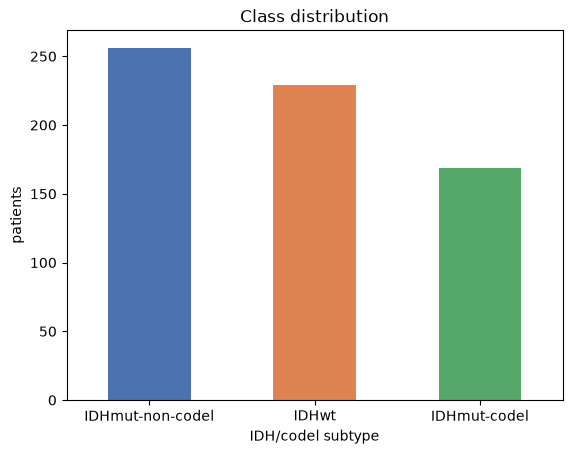

In [4]:
counts = y.value_counts()
print(counts)
counts.plot.bar(color=["#4c72b0", "#dd8452", "#55a868"], rot=0, title="Class distribution")
plt.ylabel("patients"); plt.show()

### 2.2 Data quality

In [5]:
print("missing values:", int(X.isna().sum().sum()))
print("duplicate patients:", int(X.index.duplicated().sum()))
print("genes that are zero for every patient:", int((X.sum() == 0).sum()))
print("genes that are zero for over 90% of patients:", int(((X == 0).mean() > 0.9).sum()))
print(f"genes / patients = {X.shape[1]} / {X.shape[0]}  ->  p >> n, high risk of overfitting")

missing values: 0
duplicate patients: 0
genes that are zero for every patient: 183


genes that are zero for over 90% of patients: 1879
genes / patients = 20330 / 654  ->  p >> n, high risk of overfitting


### 2.3 Distribution of expression values

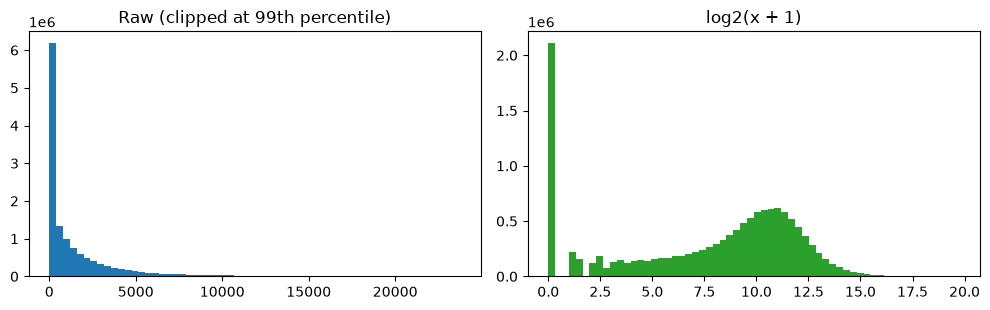

raw maximum: 884605 | median: 519.0


In [6]:
values = X.values.ravel()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(values[values < np.percentile(values, 99)], bins=60); ax[0].set_title("Raw (clipped at 99th percentile)")
ax[1].hist(np.log2(values + 1), bins=60, color="tab:green");     ax[1].set_title("log2(x + 1)")
plt.tight_layout(); plt.show()
print("raw maximum:", int(values.max()), "| median:", np.median(values))

### 2.4 Structure of the data: PCA and tumour grade

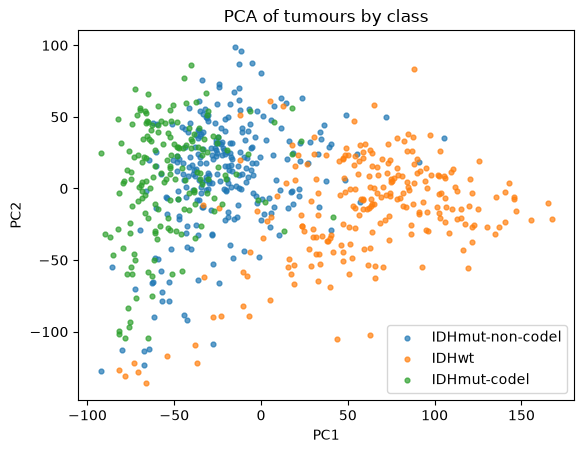

Grade               G2   G3   G4
IDH/codel subtype               
IDHmut-codel        81   70    0
IDHmut-non-codel   113  103    8
IDHwt               19   66  135


In [7]:
X_log_all = np.log2(X + 1)
pcs = PCA(2, random_state=SEED).fit_transform(StandardScaler().fit_transform(X_log_all))

for name in counts.index:
    mask = (y == name).values
    plt.scatter(pcs[mask, 0], pcs[mask, 1], s=12, alpha=.7, label=name)
plt.legend(); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA of tumours by class"); plt.show()

print(pd.crosstab(y, grade))

### 2.5 How many genes are active?

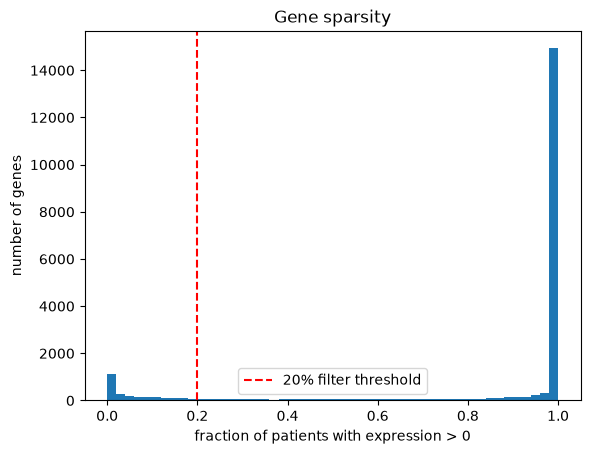

genes expressed in at least 20% of patients: 17953 of 20330


In [8]:
fraction_expressed = (X > 0).mean()                      # per gene: share of patients with expression > 0
plt.hist(fraction_expressed, bins=50, color="tab:blue")
plt.axvline(0.2, color="red", ls="--", label="20% filter threshold")
plt.xlabel("fraction of patients with expression > 0"); plt.ylabel("number of genes")
plt.title("Gene sparsity"); plt.legend(); plt.show()
print("genes expressed in at least 20% of patients:", int((fraction_expressed >= 0.2).sum()), "of", len(fraction_expressed))

### 2.6 Which genes separate the classes?
Top 30 genes by ANOVA F-score, shown as a heatmap with patients sorted by class. This is **descriptive only** and is not used to select features for the models.

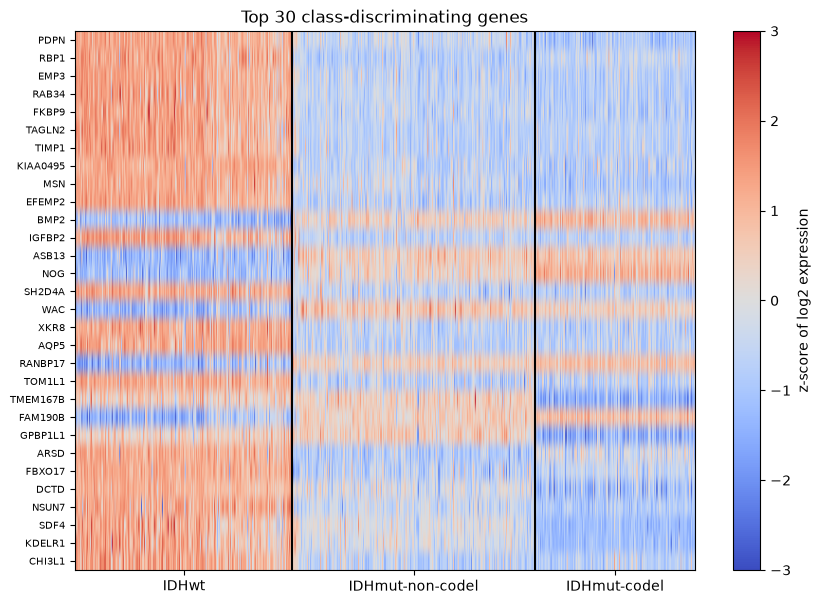

In [9]:
f_scores, _ = f_classif(X_log_all, y)
top_genes = pd.Series(f_scores, index=X_log_all.columns).fillna(0).nlargest(30).index

order = y.map({c: i for i, c in enumerate(classes)}).sort_values(kind="stable").index       # patients sorted by class
heat = X_log_all.loc[order, top_genes]
heat = (heat - heat.mean()) / heat.std()                                                    # z-score per gene

sizes = y.loc[order].value_counts().reindex(classes).values
ends = sizes.cumsum()

plt.figure(figsize=(10, 7))
plt.imshow(heat.T.values, aspect="auto", cmap="coolwarm", vmin=-3, vmax=3)
plt.yticks(range(30), top_genes, fontsize=7)
plt.xticks(ends - sizes / 2, classes)
for e in ends[:-1]:
    plt.axvline(e - 0.5, color="black", lw=1.5)
plt.colorbar(label="z-score of log2 expression"); plt.title("Top 30 class-discriminating genes"); plt.show()

**EDA findings**
- **Class balance:** IDHmut-non-codel 256, IDHwt 229, IDHmut-codel 169. Moderately imbalanced, so splits are stratified and macro-F1 is used.
- **Dimensionality:** 20,330 genes for 654 patients (p >> n), so overfitting is the main risk.
- **Data quality:** no missing values or duplicate patients. 183 genes are zero in every patient and 1,879 are zero in over 90%. Across all patients 17,953 genes are expressed in at least 20% of patients (2.5), so the 20% filter removes about 2,400 uninformative genes.
- **Skew:** raw values range up to 884,605 with a median of 519 (2.3), so a log transform is needed.
- **PCA:** IDHwt separates clearly from the IDH-mutant tumours along PC1. IDHmut-non-codel and IDHmut-codel overlap heavily in the first two components (2.4).
- **Discriminating genes (2.6):** the top 30 genes by ANOVA F-score form a clear block pattern. IDHwt is high in genes such as CHI3L1, PDPN and EMP3. The two IDH-mutant classes look similar to each other and differ mainly in a few genes (for example NOG, TMEM167B and FAM190B).
- **Grade (2.4):** IDHwt is mostly grade 4 (135 of 220 graded), IDHmut-codel has no grade 4 and IDHmut-non-codel only 8. The classes therefore partly track tumour severity.

## 3. Feature derivation and data split
1. **log2(x + 1)** - stabilises variance and removes the skew of RSEM values (a fixed transform, learns nothing from the data).
2. **Train / validation / test split** - 70% / 10% / 20%, stratified, done *before* anything is learned from the data.
3. **Low-expression filter** - keeps only genes expressed (> 0) in at least 20% of the **training** patients. This removes the all-zero and mostly-zero genes found in the EDA. The same genes are then kept in the validation and test sets.
4. **Standardisation** (logistic regression and KNN, inside their pipelines) - needed for a penalised linear model and for distance-based methods.
5. **PCA** (KNN only, inside its pipeline) - distances become uninformative in thousands of dimensions, so genes are compressed into principal components.

**How the three sets are used:** the **training set** fits the models and tunes hyperparameters (5-fold cross-validation inside it). The **validation set** is used once to choose between the tuned models. The **test set** is used once at the end for the final, unbiased scores.

### 3.1 Log transform and 70 / 10 / 20 split

In [10]:
X_log = np.log2(X + 1)

# 20% test first, then 12.5% of the remaining 80% (= 10% of all patients) as validation
X_rest, X_te, y_rest, y_te = train_test_split(X_log, y, test_size=0.20, stratify=y, random_state=SEED)
X_tr, X_va, y_tr, y_va = train_test_split(X_rest, y_rest, test_size=0.125, stratify=y_rest, random_state=SEED)

print(f"train {len(X_tr)} ({len(X_tr) / len(X):.0%}) | validation {len(X_va)} ({len(X_va) / len(X):.0%}) | test {len(X_te)} ({len(X_te) / len(X):.0%})")

train 457 (70%) | validation 66 (10%) | test 131 (20%)


### 3.2 Low-expression filter (learned from the training patients only)

In [11]:
keep = (X_tr > 0).mean() >= 0.2           # gene expressed in at least 20% of the training patients

X_tr = X_tr.loc[:, keep]
X_va = X_va.loc[:, keep]
X_te = X_te.loc[:, keep]
print("genes before filter:", len(keep), "| after filter:", X_tr.shape[1])

genes before filter: 20330 | after filter: 17963


### 3.3 Encode labels as integers (XGBoost needs 0 / 1 / 2) and check the class mix

In [12]:
code_of = {name: i for i, name in enumerate(classes)}         # IDHwt=0, IDHmut-non-codel=1, IDHmut-codel=2
y_tr, y_va, y_te = y_tr.map(code_of), y_va.map(code_of), y_te.map(code_of)

mix = pd.DataFrame({"train": y_tr.value_counts(), "validation": y_va.value_counts(), "test": y_te.value_counts()})
print(mix.rename(index=dict(enumerate(classes))))

                   train  validation  test
IDH/codel subtype                         
IDHmut-non-codel     179          26    51
IDHwt                160          23    46
IDHmut-codel         118          17    34


## 4. Base models
Every model is a scikit-learn `Pipeline`, so any scaler or PCA is fitted only on the training part of each cross-validation fold. Each model below is added to the `models` dictionary together with the hyperparameter values to search.

### 4.1 Logistic Regression
Linear softmax over standardised genes. **Regularization:** L2 penalty, strength set by `C` (small `C` = stronger penalty). **Tuned:** `C`.

In [13]:
models = {}      # name -> (pipeline, hyperparameter values to search)

models["Logistic Regression"] = (
    Pipeline([("scale", StandardScaler()),
              ("clf", LogisticRegression(solver="lbfgs", max_iter=500, random_state=SEED))]),
    {"clf__C": [0.0001, 0.001, 0.01, 0.1, 1]})

### 4.2 Decision Tree
A chain of yes/no questions about single genes. **Regularization:** depth limit, minimum leaf size, cost-complexity pruning. **Tuned:** `max_depth`, `min_samples_leaf`, `ccp_alpha`.

In [14]:
models["Decision Tree"] = (
    Pipeline([("clf", DecisionTreeClassifier(random_state=SEED))]),
    {"clf__max_depth": [3, 5, 8, None], "clf__min_samples_leaf": [1, 5, 15], "clf__ccp_alpha": [0, 0.005, 0.02]})

### 4.3 K-Nearest Neighbours
Majority vote of the most similar training patients, measured in PCA space. **Regularization:** the neighbourhood size (larger = smoother) and PCA dimension reduction. **Tuned:** `n_components`, `n_neighbors`, `weights`.

In [15]:
models["KNN"] = (
    Pipeline([("scale", StandardScaler()), ("pca", PCA(random_state=SEED)), ("clf", KNeighborsClassifier())]),
    {"pca__n_components": [10, 30], "clf__n_neighbors": [3, 7, 15, 25], "clf__weights": ["uniform", "distance"]})

## 5. Ensemble models
Two ensemble methods are used, one of each main family:
- **Random Forest (bagging):** averages many de-correlated trees grown on bootstrap samples with random feature subsets. Trees are built independently. This cuts the high *variance* of a single decision tree, so it is compared directly with the Decision Tree.
- **XGBoost (gradient boosting):** builds shallow trees one after another, and each new tree is fitted to the errors of the trees so far (it follows the gradient of the log-loss). This mainly cuts *bias*, and it is controlled with a small learning rate, shallow trees, an L2 penalty and subsampling. It is compared with the Random Forest to see whether boosting beats bagging on this data.

### 5.1 Random Forest (bagging)
**Regularization:** averaging many trees, `max_features`, `min_samples_leaf`. **Tuned:** `n_estimators`, `max_features`, `min_samples_leaf`.

In [16]:
models["Random Forest"] = (
    Pipeline([("clf", RandomForestClassifier(random_state=SEED, n_jobs=1))]),
    {"clf__n_estimators": [200, 500], "clf__max_features": ["sqrt", 0.2], "clf__min_samples_leaf": [1, 3, 8]})

### 5.2 XGBoost (boosting)
**Regularization:** shallow trees, small `learning_rate`, L2 penalty `reg_lambda`, column subsampling (`colsample_bytree`), row subsampling (`subsample=0.8`). **Tuned:** `n_estimators`, `max_depth`, `learning_rate`, `colsample_bytree`, `reg_lambda`.

In [17]:
models["XGBoost"] = (
    Pipeline([("clf", XGBClassifier(objective="multi:softprob", tree_method="hist", subsample=0.8,
                                    eval_metric="mlogloss", n_jobs=1, random_state=SEED))]),
    {"clf__n_estimators": [100, 300], "clf__max_depth": [2, 4], "clf__learning_rate": [0.05, 0.2],
     "clf__colsample_bytree": [0.2, 0.5], "clf__reg_lambda": [1, 10]})

## 6. Hyperparameter tuning
Every combination of the listed values is tried with **5-fold stratified cross-validation on the training set only**, scored on **macro-F1** (it weights the 3 classes equally despite the imbalance). The setting with the best average macro-F1 is kept for each model.

In [18]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

best = {}         # name -> fitted pipeline with the best settings
cv_score = {}     # name -> its cross-validated macro-F1

for name, (pipeline, grid) in models.items():
    workers = 4 if name == "XGBoost" else -1          # XGBoost fits are heavy: fewer parallel workers avoids running out of system resources
    search = GridSearchCV(pipeline, grid, cv=cv, scoring="f1_macro", n_jobs=workers).fit(X_tr, y_tr)
    best[name] = search.best_estimator_
    cv_score[name] = search.best_score_
    print(f"{name:20s} CV macro-F1 = {search.best_score_:.3f}")
    print("   best:", {k.split("__")[1]: v for k, v in search.best_params_.items()})

Logistic Regression  CV macro-F1 = 0.983
   best: {'C': 0.001}


Decision Tree        CV macro-F1 = 0.931
   best: {'ccp_alpha': 0, 'max_depth': 3, 'min_samples_leaf': 15}


KNN                  CV macro-F1 = 0.953
   best: {'n_neighbors': 3, 'weights': 'distance', 'n_components': 10}


Random Forest        CV macro-F1 = 0.983
   best: {'max_features': 0.2, 'min_samples_leaf': 8, 'n_estimators': 200}


XGBoost              CV macro-F1 = 0.989
   best: {'colsample_bytree': 0.2, 'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 300, 'reg_lambda': 1}


**What each hyperparameter does:** a small `C` (strong L2 penalty) shrinks gene weights towards zero and reduces overfitting; limiting tree depth and raising `min_samples_leaf` or `ccp_alpha` stops a tree memorising the training set; a small `n_neighbors` makes KNN noisy while a large one oversmooths; `max_features` decorrelates the trees of a forest; for XGBoost, a small `learning_rate` with shallow trees (`max_depth`), a larger `reg_lambda` and column subsampling all slow the model down and reduce overfitting. The best value found for each is printed above.

## 7. Performance analysis and evaluation metrics
Every tuned model is scored on the **validation set** (used to select the final model) and then on the **test set** (final, unbiased scores).

### 7.1 Validation set: choose the final model

In [19]:
val_table = pd.DataFrame({
    "CV macro-F1 (train)": pd.Series(cv_score),
    "Val accuracy":  pd.Series({n: accuracy_score(y_va, m.predict(X_va)) for n, m in best.items()}),
    "Val macro-F1":  pd.Series({n: f1_score(y_va, m.predict(X_va), average="macro") for n, m in best.items()}),
}).round(3)

selected = val_table["Val macro-F1"].idxmax()          # ties are broken by table order
print("Selected model (best validation macro-F1):", selected)
val_table.sort_values("Val macro-F1", ascending=False)

Selected model (best validation macro-F1): Random Forest


,CV macro-F1 (train),Val accuracy,Val macro-F1
Random Forest,0.983,1.000,1.000
Logistic Regression,0.983,0.985,0.986
XGBoost,0.989,0.985,0.986
Decision Tree,0.931,0.924,0.928
KNN,0.953,0.909,0.915


### 7.2 Test set: predictions of every model

In [20]:
preds  = {name: m.predict(X_te)       for name, m in best.items()}         # predicted class (0 / 1 / 2)
probas = {name: m.predict_proba(X_te) for name, m in best.items()}         # predicted class probabilities
print("test patients:", len(y_te), "| models:", list(preds))

test patients: 131 | models: ['Logistic Regression', 'Decision Tree', 'KNN', 'Random Forest', 'XGBoost']


### 7.3 Evaluation matrix (test set)
Accuracy, balanced accuracy, macro precision / recall / F1, ROC-AUC (one-vs-rest), PR-AUC, MCC, Cohen's kappa and log-loss, plus training accuracy and the **overfit gap** (training accuracy minus test accuracy).

In [21]:
rows = []
for name, m in best.items():
    p, pr = preds[name], probas[name]
    onehot = pd.get_dummies(y_te)[list(m.classes_)]                      # true classes as 0/1 columns
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_te, p),
        "Balanced acc": balanced_accuracy_score(y_te, p),
        "Macro precision": precision_score(y_te, p, average="macro"),
        "Macro recall": recall_score(y_te, p, average="macro"),
        "Macro-F1": f1_score(y_te, p, average="macro"),
        "ROC-AUC (ovr)": roc_auc_score(onehot, pr, average="macro"),
        "PR-AUC": average_precision_score(onehot, pr, average="macro"),
        "MCC": matthews_corrcoef(y_te, p),
        "Cohen kappa": cohen_kappa_score(y_te, p),
        "Log-loss": log_loss(y_te, pr, labels=list(m.classes_)),
        "Train acc": accuracy_score(y_tr, m.predict(X_tr)),
    })

eval_matrix = pd.DataFrame(rows).set_index("Model")
eval_matrix["Overfit gap"] = eval_matrix["Train acc"] - eval_matrix["Accuracy"]
eval_matrix = eval_matrix.round(3)
eval_matrix.sort_values("Macro-F1", ascending=False)

,Accuracy,Balanced acc,Macro precision,Macro recall,Macro-F1,ROC-AUC (ovr),PR-AUC,MCC,Cohen kappa,Log-loss,Train acc,Overfit gap
Model,,,,,,,,,,,,
Logistic Regression,0.985,0.987,0.981,0.987,0.984,0.992,0.980,0.977,0.977,0.098,1.000,0.015
Random Forest,0.969,0.972,0.970,0.972,0.971,0.997,0.993,0.954,0.954,0.135,0.998,0.028
XGBoost,0.969,0.972,0.968,0.972,0.970,0.999,0.998,0.954,0.954,0.077,1.000,0.031
Decision Tree,0.947,0.952,0.947,0.952,0.949,0.956,0.916,0.919,0.919,1.960,0.958,0.012
KNN,0.931,0.935,0.933,0.935,0.934,0.972,0.952,0.896,0.896,1.440,1.000,0.069


### 7.4 Confusion matrices (test set)

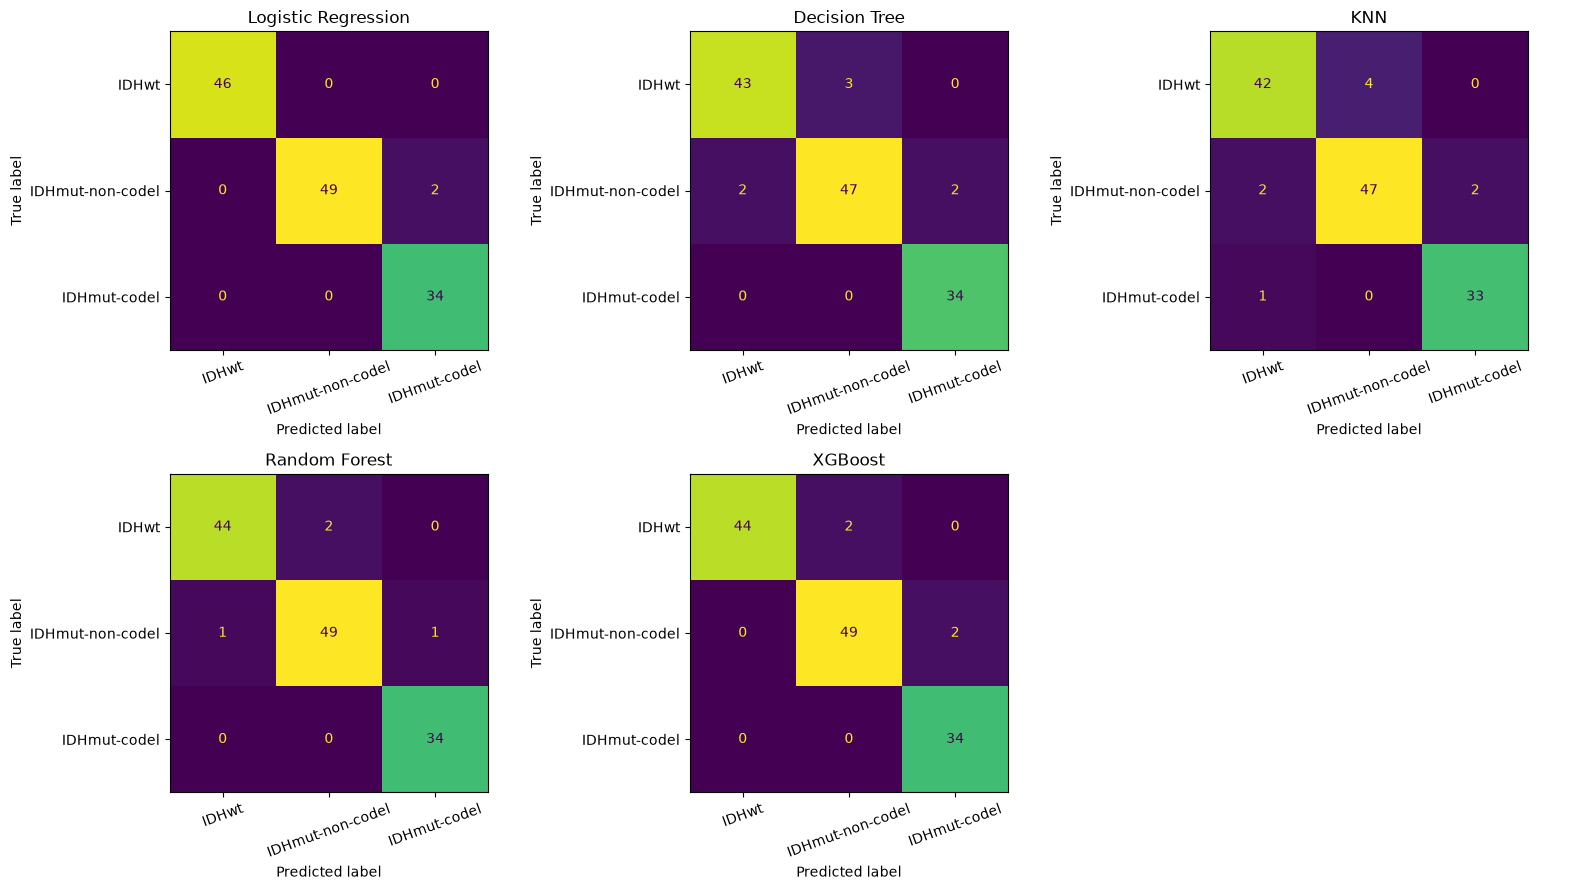

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9)); axes = axes.ravel()
for ax, name in zip(axes, preds):
    ConfusionMatrixDisplay.from_predictions(y_te, preds[name], ax=ax, colorbar=False, xticks_rotation=20,
                                            labels=[0, 1, 2], display_labels=classes)
    ax.set_title(name)
axes[-1].axis("off")
plt.tight_layout(); plt.show()

### 7.5 Per-class precision, recall and F1 of the selected model

In [23]:
print("Selected model:", selected, "\n")
print(classification_report(y_te, preds[selected], target_names=classes))

Selected model: Random Forest 

                  precision    recall  f1-score   support

           IDHwt       0.98      0.96      0.97        46
IDHmut-non-codel       0.96      0.96      0.96        51
    IDHmut-codel       0.97      1.00      0.99        34

        accuracy                           0.97       131
       macro avg       0.97      0.97      0.97       131
    weighted avg       0.97      0.97      0.97       131



### 7.6 Bootstrap 95% confidence intervals
The 131 test patients are resampled 1,000 times (with replacement) and macro-F1 is recomputed each time. If two models' intervals overlap heavily, the data cannot tell them apart.

In [24]:
rng = np.random.default_rng(SEED)
y_true = y_te.values
ci = {}                                               # name -> (lower, upper)

for name in best:
    p = preds[name]
    scores = []
    for _ in range(1000):
        pick = rng.integers(0, len(y_true), len(y_true))
        scores.append(f1_score(y_true[pick], p[pick], average="macro"))
    ci[name] = (np.percentile(scores, 2.5), np.percentile(scores, 97.5))
    print(f"{name:20s} macro-F1 = {eval_matrix.loc[name, 'Macro-F1']:.3f}   95% CI [{ci[name][0]:.3f}, {ci[name][1]:.3f}]")

Logistic Regression  macro-F1 = 0.984   95% CI [0.957, 1.000]


Decision Tree        macro-F1 = 0.949   95% CI [0.908, 0.984]


KNN                  macro-F1 = 0.934   95% CI [0.892, 0.971]


Random Forest        macro-F1 = 0.971   95% CI [0.939, 0.994]


XGBoost              macro-F1 = 0.970   95% CI [0.938, 0.993]


### 7.7 Which genes does the Random Forest rely on?

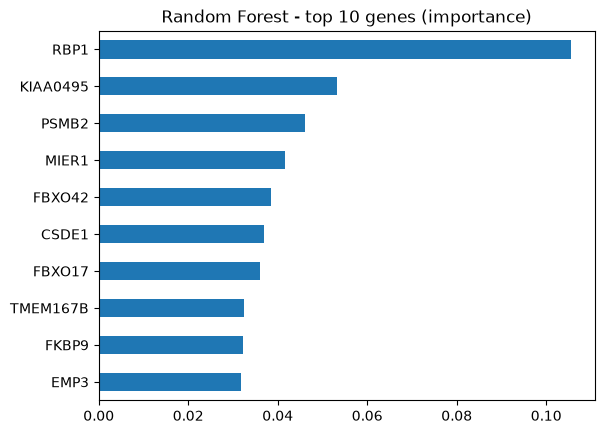

In [25]:
forest = best["Random Forest"].named_steps["clf"]
importance = pd.Series(forest.feature_importances_, index=X_tr.columns).nlargest(10)
importance.iloc[::-1].plot.barh(title="Random Forest - top 10 genes (importance)"); plt.show()

### 7.8 Interpretation
Read the tables and plots above as follows. The final numbers are summarised in the next cell and in the Conclusion.
- **Model ranking:** compare validation and test macro-F1 together. With a small test set one patient is worth about 0.8 points of accuracy, so use the bootstrap confidence intervals to judge whether differences are real.
- **Overfitting:** the overfit gap is training accuracy minus test accuracy. A large gap means the model memorised the training patients.
- **Errors:** the confusion matrices show which classes are mixed up. IDHmut-non-codel and IDHmut-codel overlap most in the PCA, so mistakes between them would be expected.
- **Macro-F1, balanced accuracy and MCC** are preferred to plain accuracy because the classes are unequal in size.
- **Genes:** the Random Forest importance plot lists the genes the forest relies on most. Importances do not prove biological mechanism.

### 7.9 Summary of the results (printed automatically)

In [26]:
cm = confusion_matrix(y_te, preds[selected], labels=[0, 1, 2])
mistakes = cm.copy()
np.fill_diagonal(mistakes, 0)                                       # keep only the wrong predictions
true_cls, pred_cls = np.unravel_index(mistakes.argmax(), mistakes.shape)

print(f"- Patients: {len(X)} total -> {len(X_tr)} train / {len(X_va)} validation / {len(X_te)} test")
print(f"- Selected model (best validation macro-F1): {selected}")
print(f"- Its test scores: accuracy {eval_matrix.loc[selected, 'Accuracy']:.3f}, macro-F1 {eval_matrix.loc[selected, 'Macro-F1']:.3f} "
      f"(95% CI {ci[selected][0]:.3f}-{ci[selected][1]:.3f}), ROC-AUC {eval_matrix.loc[selected, 'ROC-AUC (ovr)']:.3f}, MCC {eval_matrix.loc[selected, 'MCC']:.3f}")
print(f"- Its overfit gap (train - test accuracy): {eval_matrix.loc[selected, 'Overfit gap']:.3f}")
print(f"- Bagging vs single tree, test macro-F1 (Random Forest vs Decision Tree): {eval_matrix.loc['Random Forest', 'Macro-F1']:.3f} vs {eval_matrix.loc['Decision Tree', 'Macro-F1']:.3f}")
print(f"- Boosting vs bagging, test macro-F1 (XGBoost vs Random Forest): {eval_matrix.loc['XGBoost', 'Macro-F1']:.3f} vs {eval_matrix.loc['Random Forest', 'Macro-F1']:.3f}")
print(f"- Largest overfit gap: {eval_matrix['Overfit gap'].idxmax()} ({eval_matrix['Overfit gap'].max():.3f}); lowest test macro-F1: {eval_matrix['Macro-F1'].idxmin()} ({eval_matrix['Macro-F1'].min():.3f})")
if mistakes.max() > 0:
    print(f"- Most frequent error of the selected model: {classes[true_cls]} predicted as {classes[pred_cls]} ({mistakes.max()} patients)")
else:
    print("- The selected model made no errors on the test set")

- Patients: 654 total -> 457 train / 66 validation / 131 test
- Selected model (best validation macro-F1): Random Forest
- Its test scores: accuracy 0.969, macro-F1 0.971 (95% CI 0.939-0.994), ROC-AUC 0.997, MCC 0.954
- Its overfit gap (train - test accuracy): 0.028
- Bagging vs single tree, test macro-F1 (Random Forest vs Decision Tree): 0.971 vs 0.949
- Boosting vs bagging, test macro-F1 (XGBoost vs Random Forest): 0.970 vs 0.971
- Largest overfit gap: KNN (0.069); lowest test macro-F1: KNN (0.934)
- Most frequent error of the selected model: IDHwt predicted as IDHmut-non-codel (2 patients)


## 8. Conclusion
**What was expected.** The project set out to show that the three glioma types can be identified from gene activity with high accuracy, that the models rely on real biology and not noise, and how much regularization, tuning and ensembles help compared with simpler models.

**What the run shows.** The summary in 7.9 gives the selected model, its validation and test scores with a 95% confidence interval, the overfitting gap, the bagging-versus-single-tree and boosting-versus-bagging comparisons, and the most confused pair of classes.

**Limitations.**
- About 650 patients from one TCGA cohort, one split, no external validation.
- 320 of the 974 labelled patients have no expression profile, which may introduce selection bias.
- No batch or tissue-source correction.
- The validation set has only 66 patients, so the choice between close models is noisy.
- IDHwt is mostly grade 4, so part of what is learned may be tumour severity.
- Hyperparameter ranges are small, and a winner at the edge of its range may not be the true optimum.
- Research exercise only, not a validated diagnostic tool.

**Next steps.** Validate on an independent cohort, widen the tuning ranges, add SVM models, and add the chromosome-arm and pathway scores proposed in the synopsis.